<a href="https://colab.research.google.com/github/talyafirestein/glp1-prescription-socioeconomic-analysis/blob/main/GLP1_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# STOR 320: Methods for Data Science
## EDA Group #4
#### Group members: Aerin Borden, Talya Firestein, Evelyn Galvan, Estella Li, Hannah Tran

**Please Mark Your Name Next to Which Proposal Questions You're Doing:**


1. Evelyn
2. Hannah
3. Talya
4. Estella
5. Evelyn
6. Talya
7. Estella
8. Aerin
9. Hannah
10. Aerin





## Introduction

[Describe datasets here]

In this notebook, we will perform EDA to understand the data, identify patterns, detect anomalies, and extract insights that could be useful for predictive modeling.

## Objectives

- Understand the structure and content of the dataset.
- Handle missing values appropriately.
- Explore distributions of individual variables.
- Identify key features that influence house prices.

## Dataset Description

Some of the key variables in the dataset include:

[Variable Name]: What it is

# Part 0: Unpack the Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
census_2024 = pd.read_csv("https://raw.githubusercontent.com/estellayl/stor320-colab-data/refs/heads/main/census%20data%20(2024).csv")
census_2024.head()

,Label (Grouping),Alabama!!Estimate,Alabama!!Margin of Error,Alabama!!Percent,Alabama!!Percent Margin of Error,Alaska!!Estimate,Alaska!!Margin of Error,Alaska!!Percent,Alaska!!Percent Margin of Error,Arizona!!Estimate,...,Wisconsin!!Percent,Wisconsin!!Percent Margin of Error,Wyoming!!Estimate,Wyoming!!Margin of Error,Wyoming!!Percent,Wyoming!!Percent Margin of Error,Puerto Rico!!Estimate,Puerto Rico!!Margin of Error,Puerto Rico!!Percent,Puerto Rico!!Percent Margin of Error
0,EMPLOYMENT STATUS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Population 16 years and over,"4,160,138","±4,725","4,160,138",(X),"586,083","±1,667","586,083",(X),"6,193,806",...,"4,882,973",(X),"480,483","±2,259","480,483",(X),"2,796,511","±3,432","2,796,511",(X)
2,In labor force,"2,463,085","±17,131",59.2%,±0.4,"390,591","±5,285",66.6%,±0.9,"3,802,740",...,65.4%,±0.3,"311,849","±5,140",64.9%,±1.0,"1,328,934","±15,522",47.5%,±0.6
3,Civilian labor force,"2,447,875","±17,498",58.8%,±0.4,"363,709","±5,489",62.1%,±0.9,"3,778,884",...,65.3%,±0.3,"307,647","±5,376",64.0%,±1.0,"1,325,458","±15,727",47.4%,±0.6
4,Employed,"2,344,294","±17,303",56.4%,±0.4,"342,028","±5,975",58.4%,±1.0,"3,606,425",...,63.3%,±0.3,"297,101","±5,684",61.8%,±1.1,"1,213,487","±16,481",43.4%,±0.6


In [ ]:
census_2024.describe()

,Label (Grouping),Alabama!!Estimate,Alabama!!Margin of Error,Alabama!!Percent,Alabama!!Percent Margin of Error,Alaska!!Estimate,Alaska!!Margin of Error,Alaska!!Percent,Alaska!!Percent Margin of Error,Arizona!!Estimate,...,Wisconsin!!Percent,Wisconsin!!Percent Margin of Error,Wyoming!!Estimate,Wyoming!!Margin of Error,Wyoming!!Percent,Wyoming!!Percent Margin of Error,Puerto Rico!!Estimate,Puerto Rico!!Margin of Error,Puerto Rico!!Percent,Puerto Rico!!Percent Margin of Error
count,145,137,137,137,137,137,137,137,137,137,...,137,137,137,137,137,137,137,137,137,137
unique,122,114,112,109,21,114,113,109,30,114,...,104,20,113,111,112,33,114,113,109,28
top,Civilian employed population 16 years and ...,(X),(X),(X),(X),(X),(X),(X),(X),(X),...,(X),(X),(X),(X),(X),(X),(X),(X),(X),(X)
freq,3,20,20,16,35,20,20,16,35,20,...,16,35,20,20,16,35,20,20,16,35


In [ ]:
glp_data_2024 = pd.read_csv("https://raw.githubusercontent.com/estellayl/stor320-colab-data/refs/heads/main/2024_selected_drugs.csv")
glp_data_2024.head()

,Prscrbr_Geo_Lvl,Prscrbr_Geo_Cd,Prscrbr_Geo_Desc,Brnd_Name,Gnrc_Name,Tot_Prscrbrs,Tot_Clms,Tot_30day_Fills,Tot_Drug_Cst,Tot_Benes,...,GE65_Tot_30day_Fills,GE65_Tot_Drug_Cst,GE65_Bene_Sprsn_Flag,GE65_Tot_Benes,LIS_Bene_Cst_Shr,NonLIS_Bene_Cst_Shr,Opioid_Drug_Flag,Opioid_LA_Drug_Flag,Antbtc_Drug_Flag,Antpsyct_Drug_Flag
0,National,NaN,National,Liraglutide,Liraglutide,18209,62242,85916.3,4.808463e+07,24400.0,...,74920.8,4.151801e+07,NaN,21044.0,57311.29,2.851477e+06,N,N,N,N
1,National,NaN,National,Mounjaro,Tirzepatide,194653,5103556,6093348.5,6.334739e+09,894243.0,...,4569326.9,4.733920e+09,NaN,679553.0,7237215.22,3.779843e+08,N,N,N,N
2,National,NaN,National,Ozempic,Semaglutide,286517,10413554,14353450.6,1.296581e+10,1951892.0,...,11218675.4,1.010153e+10,NaN,1533376.0,16408117.89,7.558856e+08,N,N,N,N
3,National,NaN,National,Rybelsus,Semaglutide,125776,1251182,2063083.7,1.889262e+09,309850.0,...,1749352.6,1.597996e+09,NaN,262141.0,2020902.37,8.833839e+07,N,N,N,N
4,National,NaN,National,Trulicity,Dulaglutide,216578,4303409,5748807.1,5.452032e+09,788414.0,...,4633422.9,4.387163e+09,NaN,627043.0,7046123.42,2.515434e+08,N,N,N,N


In [ ]:
glp_data_2024.describe()

,Tot_Prscrbrs,Tot_Clms,Tot_30day_Fills,Tot_Drug_Cst,Tot_Benes,GE65_Tot_Clms,GE65_Tot_30day_Fills,GE65_Tot_Drug_Cst,GE65_Tot_Benes,LIS_Bene_Cst_Shr,NonLIS_Bene_Cst_Shr
count,516.000000,5.160000e+02,5.160000e+02,5.160000e+02,5.030000e+02,4.900000e+02,4.900000e+02,4.900000e+02,4.530000e+02,5.160000e+02,5.160000e+02
mean,3765.269380,8.407897e+04,1.128049e+05,1.060598e+08,1.670330e+04,6.860067e+04,9.336036e+04,8.738239e+07,1.459241e+04,1.305497e+05,5.920550e+06
std,19112.870444,5.527889e+05,7.447187e+05,6.907456e+08,1.039963e+05,4.373192e+05,5.972459e+05,5.515873e+08,8.586909e+04,8.625156e+05,3.937820e+07
min,1.000000,1.100000e+01,1.100000e+01,8.654230e+03,1.100000e+01,1.100000e+01,1.100000e+01,8.654230e+03,1.100000e+01,0.000000e+00,0.000000e+00
25%,171.500000,7.362500e+02,1.065950e+03,7.875083e+05,2.665000e+02,7.827500e+02,1.164225e+03,7.906309e+05,3.470000e+02,8.840750e+02,4.472609e+04
50%,659.500000,3.528000e+03,4.974550e+03,4.026292e+06,1.161000e+03,3.336000e+03,4.666050e+03,4.282313e+06,1.266000e+03,6.010285e+03,2.884312e+05
75%,2312.750000,3.523325e+04,4.769035e+04,4.576049e+07,7.652500e+03,3.077950e+04,4.357968e+04,4.163561e+07,7.823000e+03,5.291976e+04,2.795217e+06
max,286517.000000,1.041355e+07,1.435345e+07,1.296581e+10,1.951892e+06,8.040161e+06,1.121868e+07,1.010153e+10,1.533376e+06,1.640812e+07,7.558856e+08


## Part 1: Data cleaning, merging, and visualization (6 points)

In [ ]:
## column names check (1 point)
print(list(glp_data_2024.columns))

['Prscrbr_Geo_Lvl', 'Prscrbr_Geo_Cd', 'Prscrbr_Geo_Desc', 'Brnd_Name', 'Gnrc_Name', 'Tot_Prscrbrs', 'Tot_Clms', 'Tot_30day_Fills', 'Tot_Drug_Cst', 'Tot_Benes', 'GE65_Sprsn_Flag', 'GE65_Tot_Clms', 'GE65_Tot_30day_Fills', 'GE65_Tot_Drug_Cst', 'GE65_Bene_Sprsn_Flag', 'GE65_Tot_Benes', 'LIS_Bene_Cst_Shr', 'NonLIS_Bene_Cst_Shr', 'Opioid_Drug_Flag', 'Opioid_LA_Drug_Flag', 'Antbtc_Drug_Flag', 'Antpsyct_Drug_Flag']


In [ ]:
glp_data_2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 516 entries, 0 to 515
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Prscrbr_Geo_Lvl       516 non-null    object 
 1   Prscrbr_Geo_Cd        506 non-null    object 
 2   Prscrbr_Geo_Desc      516 non-null    object 
 3   Brnd_Name             516 non-null    object 
 4   Gnrc_Name             516 non-null    object 
 5   Tot_Prscrbrs          516 non-null    int64  
 6   Tot_Clms              516 non-null    int64  
 7   Tot_30day_Fills       516 non-null    float64
 8   Tot_Drug_Cst          516 non-null    float64
 9   Tot_Benes             503 non-null    float64
 10  GE65_Sprsn_Flag       26 non-null     object 
 11  GE65_Tot_Clms         490 non-null    float64
 12  GE65_Tot_30day_Fills  490 non-null    float64
 13  GE65_Tot_Drug_Cst     490 non-null    float64
 14  GE65_Bene_Sprsn_Flag  63 non-null     object 
 15  GE65_Tot_Benes        4

In [ ]:
print(list(census_2024.columns))

['Label (Grouping)', 'Alabama!!Estimate', 'Alabama!!Margin of Error', 'Alabama!!Percent', 'Alabama!!Percent Margin of Error', 'Alaska!!Estimate', 'Alaska!!Margin of Error', 'Alaska!!Percent', 'Alaska!!Percent Margin of Error', 'Arizona!!Estimate', 'Arizona!!Margin of Error', 'Arizona!!Percent', 'Arizona!!Percent Margin of Error', 'Arkansas!!Estimate', 'Arkansas!!Margin of Error', 'Arkansas!!Percent', 'Arkansas!!Percent Margin of Error', 'California!!Estimate', 'California!!Margin of Error', 'California!!Percent', 'California!!Percent Margin of Error', 'Colorado!!Estimate', 'Colorado!!Margin of Error', 'Colorado!!Percent', 'Colorado!!Percent Margin of Error', 'Connecticut!!Estimate', 'Connecticut!!Margin of Error', 'Connecticut!!Percent', 'Connecticut!!Percent Margin of Error', 'Delaware!!Estimate', 'Delaware!!Margin of Error', 'Delaware!!Percent', 'Delaware!!Percent Margin of Error', 'District of Columbia!!Estimate', 'District of Columbia!!Margin of Error', 'District of Columbia!!Perce

In [ ]:
census_2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145 entries, 0 to 144
Columns: 209 entries, Label (Grouping) to Puerto Rico!!Percent Margin of Error
dtypes: object(209)
memory usage: 236.9+ KB


In [ ]:
## missing data check (1 point)

In [ ]:
print(glp_data_2024.isna().sum())

Prscrbr_Geo_Lvl           0
Prscrbr_Geo_Cd           10
Prscrbr_Geo_Desc          0
Brnd_Name                 0
Gnrc_Name                 0
Tot_Prscrbrs              0
Tot_Clms                  0
Tot_30day_Fills           0
Tot_Drug_Cst              0
Tot_Benes                13
GE65_Sprsn_Flag         490
GE65_Tot_Clms            26
GE65_Tot_30day_Fills     26
GE65_Tot_Drug_Cst        26
GE65_Bene_Sprsn_Flag    453
GE65_Tot_Benes           63
LIS_Bene_Cst_Shr          0
NonLIS_Bene_Cst_Shr       0
Opioid_Drug_Flag          0
Opioid_LA_Drug_Flag       0
Antbtc_Drug_Flag          0
Antpsyct_Drug_Flag        0
dtype: int64


In [ ]:
print(census_2024.isna().sum())

Label (Grouping)                        0
Alabama!!Estimate                       8
Alabama!!Margin of Error                8
Alabama!!Percent                        8
Alabama!!Percent Margin of Error        8
                                       ..
Wyoming!!Percent Margin of Error        8
Puerto Rico!!Estimate                   8
Puerto Rico!!Margin of Error            8
Puerto Rico!!Percent                    8
Puerto Rico!!Percent Margin of Error    8
Length: 209, dtype: int64


In [ ]:
## Outlier check (1 point)

           Tot_Clms  Tot_Drug_Cst     Tot_Benes   Tot_Prscrbrs
count  5.160000e+02  5.160000e+02  5.030000e+02     516.000000
mean   8.407897e+04  1.060598e+08  1.670330e+04    3765.269380
std    5.527889e+05  6.907456e+08  1.039963e+05   19112.870444
min    1.100000e+01  8.654230e+03  1.100000e+01       1.000000
25%    7.362500e+02  7.875083e+05  2.665000e+02     171.500000
50%    3.528000e+03  4.026292e+06  1.161000e+03     659.500000
75%    3.523325e+04  4.576049e+07  7.652500e+03    2312.750000
max    1.041355e+07  1.296581e+10  1.951892e+06  286517.000000
Top 5 by Tot_Clms
   Prscrbr_Geo_Lvl Prscrbr_Geo_Desc  Brnd_Name  Tot_Clms
2         National         National    Ozempic  10413554
1         National         National   Mounjaro   5103556
4         National         National  Trulicity   4303409
3         National         National   Rybelsus   1251182
48           State       California    Ozempic   1000639
Bottom 5 by Tot_Clms
    Prscrbr_Geo_Lvl      Prscrbr_Geo_Desc      Brnd_

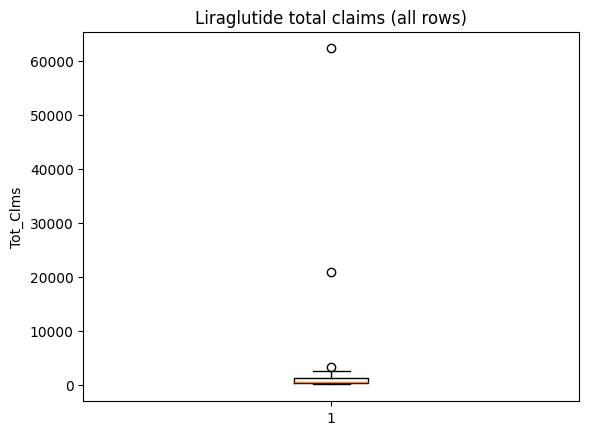

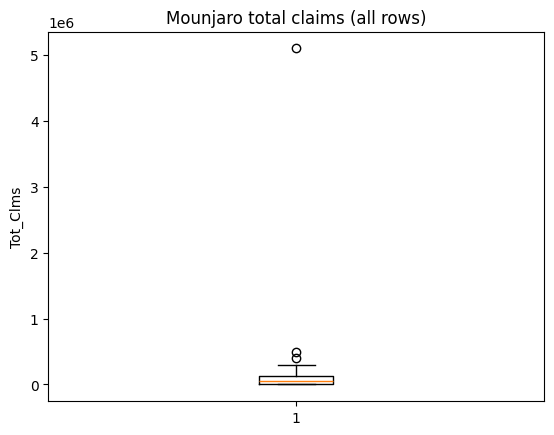

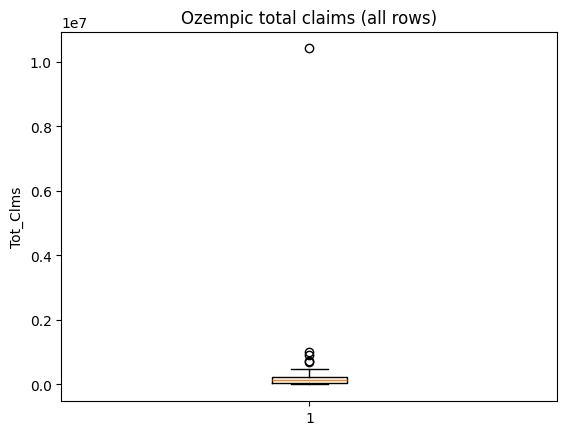

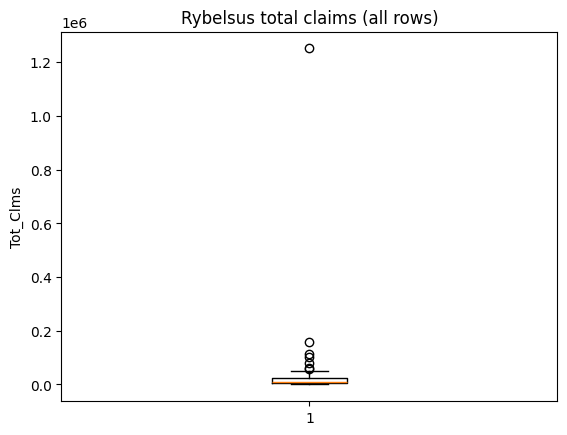

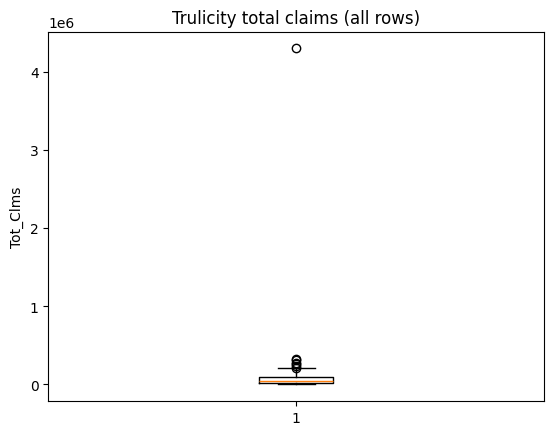

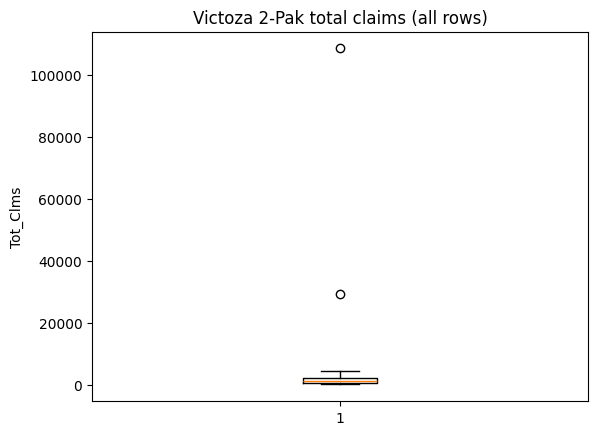

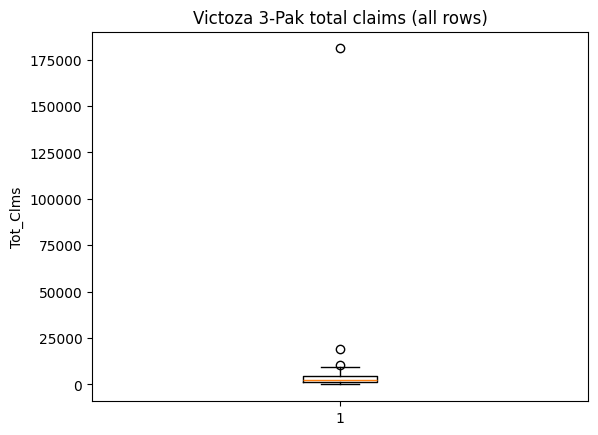

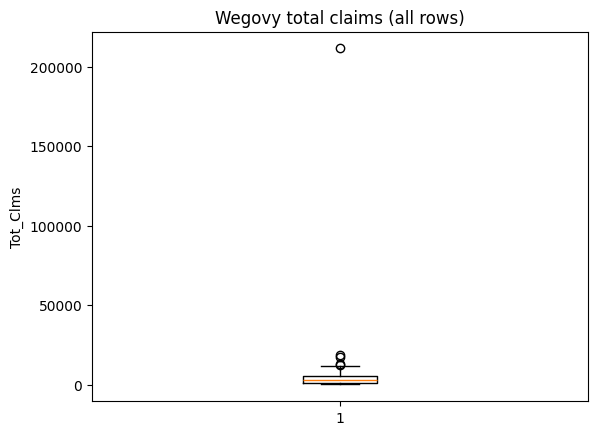

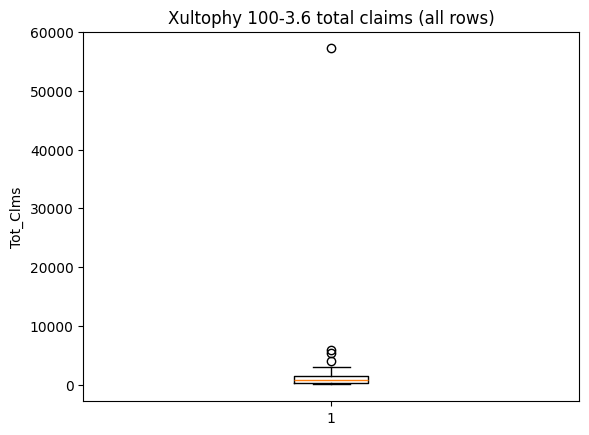

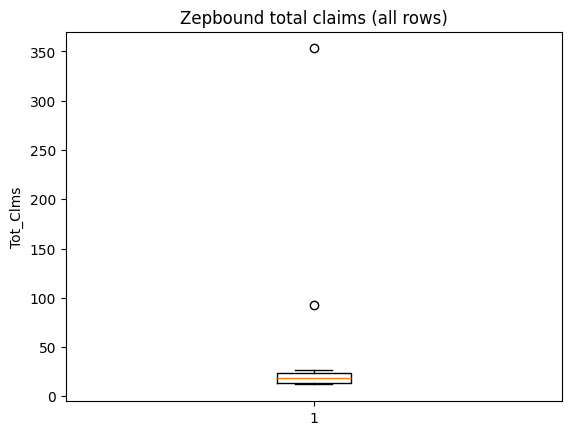

In [ ]:
glp_cols = ['Tot_Clms', 'Tot_Drug_Cst', 'Tot_Benes', 'Tot_Prscrbrs']
print(glp_data_2024[glp_cols].describe())

for col in ['Tot_Clms', 'Tot_Drug_Cst']:
    print('Top 5 by', col)
    top = glp_data_2024.sort_values(col, ascending=False).head(5)
    print(top[['Prscrbr_Geo_Lvl', 'Prscrbr_Geo_Desc', 'Brnd_Name', col]])
    print('Bottom 5 by', col)
    bottom = glp_data_2024.sort_values(col, ascending=True).head(5)
    print(bottom[['Prscrbr_Geo_Lvl', 'Prscrbr_Geo_Desc', 'Brnd_Name', col]])

drug_list = glp_data_2024['Brnd_Name'].unique()
for drug in drug_list:
    specific = glp_data_2024[glp_data_2024['Brnd_Name'] == drug]
    plt.boxplot(specific['Tot_Clms'])
    plt.title(drug + ' total claims (all rows)')
    plt.ylabel('Tot_Clms')
    plt.show()

Because of how Census is, we need to make a consolidated State column somehow so that we can merge it with the GLP data. Right now, we have multiple columns for each state, but we want a bunch of rows with these factors but the state is a column.

In [ ]:
# We want to eventually merge on "State"
# Easy part is to rename the column for teh glp data lol
glp_data_2024 = glp_data_2024.rename(columns={'Prscrbr_Geo_Desc': 'State'})
glp_data_2024 = glp_data_2024[glp_data_2024['State'] != 'Puerto Rico']

# reload the original census file, then cut it down
census_2024['Label (Grouping)'] = census_2024['Label (Grouping)'].str.strip()
census_2024 = census_2024[census_2024['Alabama!!Estimate'].notna()]

In [ ]:
## data transformation, normalization, and cleaning (1 point)

In [ ]:
glp_data_2024 = glp_data_2024.rename(columns={
    'Prscrbr_Geo_Lvl': 'geo_level',
    'Prscrbr_Geo_Cd': 'geo_code',
    'Prscrbr_Geo_Desc': 'State',
    'Brnd_Name': 'brand_name',
    'Gnrc_Name': 'generic_name',
    'Tot_Prscrbrs': 'total_prescribers',
    'Tot_Clms': 'total_claims',
    'Tot_30day_Fills': 'total_30day_fills',
    'Tot_Drug_Cst': 'total_drug_cost',
    'Tot_Benes': 'total_beneficiaries',
    'GE65_Sprsn_Flag': 'age65_claims_suppression_flag',
    'GE65_Tot_Clms': 'age65_total_claims',
    'GE65_Tot_30day_Fills': 'age65_total_30day_fills',
    'GE65_Tot_Drug_Cst': 'age65_total_drug_cost',
    'GE65_Bene_Sprsn_Flag': 'age65_benes_suppression_flag',
    'GE65_Tot_Benes': 'age65_total_beneficiaries',
    'LIS_Bene_Cst_Shr': 'lis_bene_cost_share',
    'NonLIS_Bene_Cst_Shr': 'non_lis_bene_cost_share',
    'Opioid_Drug_Flag': 'opioid_flag',
    'Opioid_LA_Drug_Flag': 'long_acting_opioid_flag',
    'Antbtc_Drug_Flag': 'antibiotic_flag',
    'Antpsyct_Drug_Flag': 'antipsychotic_flag'})
print(list(glp_data_2024.columns))

['geo_level', 'geo_code', 'State', 'brand_name', 'generic_name', 'total_prescribers', 'total_claims', 'total_30day_fills', 'total_drug_cost', 'total_beneficiaries', 'age65_claims_suppression_flag', 'age65_total_claims', 'age65_total_30day_fills', 'age65_total_drug_cost', 'age65_benes_suppression_flag', 'age65_total_beneficiaries', 'lis_bene_cost_share', 'non_lis_bene_cost_share', 'opioid_flag', 'long_acting_opioid_flag', 'antibiotic_flag', 'antipsychotic_flag']


In [ ]:
census_2024['Label (Grouping)'] = (
    census_2024['Label (Grouping)'].str.strip()
)

census_2024 = census_2024[
    census_2024['Alabama!!Estimate'].notna()
].copy()

census_2024.head()

,Label (Grouping),Alabama!!Estimate,Alabama!!Margin of Error,Alabama!!Percent,Alabama!!Percent Margin of Error,Alaska!!Estimate,Alaska!!Margin of Error,Alaska!!Percent,Alaska!!Percent Margin of Error,Arizona!!Estimate,...,Wisconsin!!Percent,Wisconsin!!Percent Margin of Error,Wyoming!!Estimate,Wyoming!!Margin of Error,Wyoming!!Percent,Wyoming!!Percent Margin of Error,Puerto Rico!!Estimate,Puerto Rico!!Margin of Error,Puerto Rico!!Percent,Puerto Rico!!Percent Margin of Error
1,Population 16 years and over,"4,160,138","±4,725","4,160,138",(X),"586,083","±1,667","586,083",(X),"6,193,806",...,"4,882,973",(X),"480,483","±2,259","480,483",(X),"2,796,511","±3,432","2,796,511",(X)
2,In labor force,"2,463,085","±17,131",59.2%,±0.4,"390,591","±5,285",66.6%,±0.9,"3,802,740",...,65.4%,±0.3,"311,849","±5,140",64.9%,±1.0,"1,328,934","±15,522",47.5%,±0.6
3,Civilian labor force,"2,447,875","±17,498",58.8%,±0.4,"363,709","±5,489",62.1%,±0.9,"3,778,884",...,65.3%,±0.3,"307,647","±5,376",64.0%,±1.0,"1,325,458","±15,727",47.4%,±0.6
4,Employed,"2,344,294","±17,303",56.4%,±0.4,"342,028","±5,975",58.4%,±1.0,"3,606,425",...,63.3%,±0.3,"297,101","±5,684",61.8%,±1.1,"1,213,487","±16,481",43.4%,±0.6
5,Unemployed,"103,581","±7,618",2.5%,±0.2,"21,681","±2,361",3.7%,±0.4,"172,459",...,2.0%,±0.1,"10,546","±2,010",2.2%,±0.4,"111,971","±7,640",4.0%,±0.3


In [ ]:
census_long = census_2024.melt(
    id_vars=['Label (Grouping)'],
    var_name='State_Measure',
    value_name='Value'
)

census_long.head()

,Label (Grouping),State_Measure,Value
0,Population 16 years and over,Alabama!!Estimate,"4,160,138"
1,In labor force,Alabama!!Estimate,"2,463,085"
2,Civilian labor force,Alabama!!Estimate,"2,447,875"
3,Employed,Alabama!!Estimate,"2,344,294"
4,Unemployed,Alabama!!Estimate,"103,581"


In [ ]:
census_long[['State', 'Measure']] = (
    census_long['State_Measure'].str.split(
        '!!', n=1, expand=True
    )
)

census_long.head()

,Label (Grouping),State_Measure,Value,State,Measure
0,Population 16 years and over,Alabama!!Estimate,"4,160,138",Alabama,Estimate
1,In labor force,Alabama!!Estimate,"2,463,085",Alabama,Estimate
2,Civilian labor force,Alabama!!Estimate,"2,447,875",Alabama,Estimate
3,Employed,Alabama!!Estimate,"2,344,294",Alabama,Estimate
4,Unemployed,Alabama!!Estimate,"103,581",Alabama,Estimate


In [ ]:
census_estimates = census_long[
    census_long['Measure'] == 'Estimate'
].copy()

census_estimates['Value'] = pd.to_numeric(
    census_estimates['Value'].str.replace(',', '', regex=False),
    errors='coerce'
)

census_estimates.head()

,Label (Grouping),State_Measure,Value,State,Measure
0,Population 16 years and over,Alabama!!Estimate,4160138.0,Alabama,Estimate
1,In labor force,Alabama!!Estimate,2463085.0,Alabama,Estimate
2,Civilian labor force,Alabama!!Estimate,2447875.0,Alabama,Estimate
3,Employed,Alabama!!Estimate,2344294.0,Alabama,Estimate
4,Unemployed,Alabama!!Estimate,103581.0,Alabama,Estimate


In [ ]:
keywords = ['income', 'poverty', 'unemploy']

economic_rows = census_2024[
    census_2024['Label (Grouping)'].str.contains(
        '|'.join(keywords), case=False, na=False
    )
]

print(economic_rows['Label (Grouping)'].unique())

['Unemployed' 'Unemployment Rate' 'Median household income (dollars)'
 'Mean household income (dollars)' 'Mean Social Security income (dollars)'
 'With retirement income' 'Mean retirement income (dollars)'
 'With Supplemental Security Income'
 'Mean Supplemental Security Income (dollars)'
 'With cash public assistance income'
 'Mean cash public assistance income (dollars)'
 'Median family income (dollars)' 'Mean family income (dollars)'
 'Per capita income (dollars)' 'Median nonfamily income (dollars)'
 'Mean nonfamily income (dollars)' 'Unemployed:']


In [ ]:
economic_rows[
    ['Label (Grouping)', 'Alabama!!Estimate', 'Alabama!!Percent']
]

,Label (Grouping),Alabama!!Estimate,Alabama!!Percent
5,Unemployed,"103,581",2.5%
9,Unemployment Rate,(X),4.2%
67,Median household income (dollars),"66,659",(X)
68,Mean household income (dollars),"90,741",(X)
72,Mean Social Security income (dollars),"24,199",(X)
73,With retirement income,"523,035",25.4%
74,Mean retirement income (dollars),"29,201",(X)
75,With Supplemental Security Income,"131,556",6.4%
76,Mean Supplemental Security Income (dollars),"11,156",(X)
77,With cash public assistance income,"28,919",1.4%


In [ ]:
def get_variable(label, measure, new_name):
    result = census_long[
        (census_long['Label (Grouping)'] == label) &
        (census_long['Measure'] == measure)
    ][['State', 'Value']].copy()

    return result.rename(columns={'Value': new_name})


income = get_variable(
    'Median household income (dollars)',
    'Estimate',
    'median_income'
)

unemployment = get_variable(
    'Unemployment Rate',
    'Percent',
    'unemployment_rate'
)

poverty = get_variable(
    'All people',
    'Percent',
    'poverty_rate'
)

print(poverty.head())


           State poverty_rate
401      Alabama        15.2%
949       Alaska        10.2%
1497     Arizona        11.7%
2045    Arkansas        15.5%
2593  California        11.8%


In [ ]:
census_clean = income.merge(
    unemployment,
    on='State',
    how='left',
    validate='one_to_one'
)

census_clean = census_clean.merge(
    poverty,
    on='State',
    how='left',
    validate='one_to_one'
)

for col in ['median_income', 'unemployment_rate', 'poverty_rate']:
    census_clean[col] = pd.to_numeric(
        census_clean[col].astype(str)
        .str.replace(',', '', regex=False)
        .str.replace('%', '', regex=False),
        errors='coerce'
    )

census_clean = census_clean[
    census_clean['State'] != 'Puerto Rico'
].copy()

display(census_clean.head())

print(census_clean.columns.tolist())


,State,median_income,unemployment_rate,poverty_rate
0,Alabama,66659,4.2,15.2
1,Alaska,95665,6.0,10.2
2,Arizona,81486,4.6,11.7
3,Arkansas,62106,3.8,15.5
4,California,100149,5.9,11.8


['State', 'median_income', 'unemployment_rate', 'poverty_rate']


In [ ]:
## data merging (1 point)

In [ ]:
glp_states = set(glp_data_2024['State'].dropna().unique())
census_states = set(census_clean['State'].dropna().unique())

print("States in GLP data but not Census:")
print(sorted(glp_states - census_states))

print("\nStates in Census but not GLP data:")
print(sorted(census_states - glp_states))

States in GLP data but not Census:
['Armed Forces Europe', 'Armed Forces Pacific', 'Foreign Country', 'Guam', 'National', 'Northern Mariana Islands', 'Unknown', 'Virgin Islands']

States in Census but not GLP data:
[]


In [ ]:
glp_clean = glp_data_2024.copy()

glp_clean = glp_clean[
    glp_clean['State'].isin(census_clean['State'])
].copy()

print("Cleaned GLP-1 data:")
display(glp_clean.head())

Cleaned GLP-1 data:


,geo_level,geo_code,State,brand_name,generic_name,total_prescribers,total_claims,total_30day_fills,total_drug_cost,total_beneficiaries,...,age65_total_30day_fills,age65_total_drug_cost,age65_benes_suppression_flag,age65_total_beneficiaries,lis_bene_cost_share,non_lis_bene_cost_share,opioid_flag,long_acting_opioid_flag,antibiotic_flag,antipsychotic_flag
10,State,01,Alabama,Liraglutide,Liraglutide,200,461,727.0,4.137233e+05,212.0,...,663.4,3.768791e+05,NaN,191.0,184.80,19293.93,N,N,N,N
11,State,01,Alabama,Mounjaro,Tirzepatide,3749,175463,202481.0,2.126128e+08,28948.0,...,132731.4,1.386409e+08,NaN,19422.0,264259.95,9023406.90,N,N,N,N
12,State,01,Alabama,Ozempic,Semaglutide,4238,226792,300214.0,2.734156e+08,43682.0,...,215484.4,1.953328e+08,NaN,31479.0,363577.40,13090612.42,N,N,N,N
13,State,01,Alabama,Rybelsus,Semaglutide,2318,29619,46573.7,4.324649e+07,7371.0,...,36683.1,3.393582e+07,NaN,5758.0,53010.86,1655845.17,N,N,N,N
14,State,01,Alabama,Trulicity,Dulaglutide,3254,72663,91879.1,8.799995e+07,13666.0,...,69014.7,6.584581e+07,NaN,10039.0,117025.75,3300031.82,N,N,N,N


In [ ]:
merged_data = pd.merge(
    glp_clean,
    census_clean,
    on='State',
    how='left',
    validate='many_to_one'
)

print("Merged dataset:")
display(merged_data.head())


Merged dataset:


,geo_level,geo_code,State,brand_name,generic_name,total_prescribers,total_claims,total_30day_fills,total_drug_cost,total_beneficiaries,...,age65_total_beneficiaries,lis_bene_cost_share,non_lis_bene_cost_share,opioid_flag,long_acting_opioid_flag,antibiotic_flag,antipsychotic_flag,median_income,unemployment_rate,poverty_rate
0,State,01,Alabama,Liraglutide,Liraglutide,200,461,727.0,4.137233e+05,212.0,...,191.0,184.80,19293.93,N,N,N,N,66659,4.2,15.2
1,State,01,Alabama,Mounjaro,Tirzepatide,3749,175463,202481.0,2.126128e+08,28948.0,...,19422.0,264259.95,9023406.90,N,N,N,N,66659,4.2,15.2
2,State,01,Alabama,Ozempic,Semaglutide,4238,226792,300214.0,2.734156e+08,43682.0,...,31479.0,363577.40,13090612.42,N,N,N,N,66659,4.2,15.2
3,State,01,Alabama,Rybelsus,Semaglutide,2318,29619,46573.7,4.324649e+07,7371.0,...,5758.0,53010.86,1655845.17,N,N,N,N,66659,4.2,15.2
4,State,01,Alabama,Trulicity,Dulaglutide,3254,72663,91879.1,8.799995e+07,13666.0,...,10039.0,117025.75,3300031.82,N,N,N,N,66659,4.2,15.2


In [ ]:
print("Number of states:", merged_data['State'].nunique())
print("Number of prescription records:", len(merged_data))

print("\nMissing economic values:")
print(
    merged_data[
        ['median_income', 'unemployment_rate', 'poverty_rate']
    ].isna().sum()
)


Number of states: 51
Number of prescription records: 469

Missing economic values:
median_income        0
unemployment_rate    0
poverty_rate         0
dtype: int64


In [ ]:
## Exploratory data visualization (1 point)

In [ ]:
state_summary = merged_data.groupby('State').agg(
    total_claims=('total_claims', 'sum'),
    median_income=('median_income', 'first'),
    unemployment_rate=('unemployment_rate', 'first'),
    poverty_rate=('poverty_rate', 'first')
).reset_index()

state_summary.head()


,State,total_claims,median_income,unemployment_rate,poverty_rate
0,Alabama,512693,66659,4.2,15.2
1,Alaska,33784,95665,6.0,10.2
2,Arizona,363728,81486,4.6,11.7
3,Arkansas,252388,62106,3.8,15.5
4,California,1857791,100149,5.9,11.8


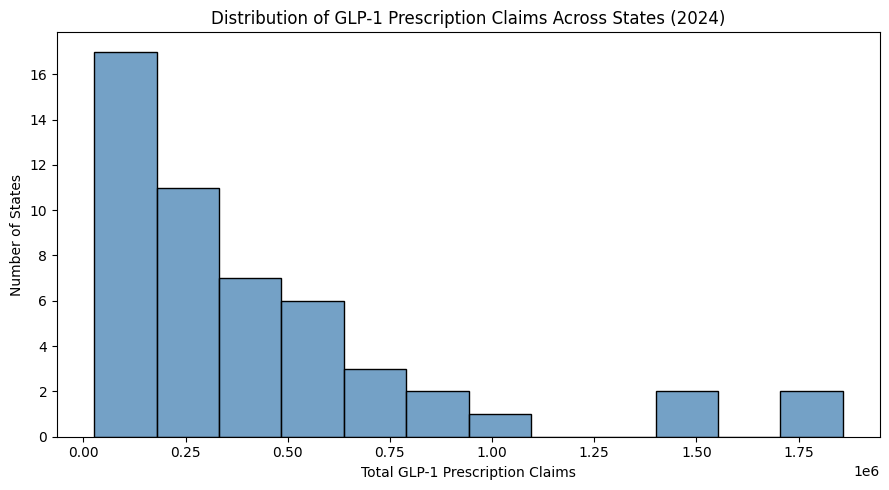

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=state_summary,
    x='total_claims',
    bins=12,
    color='steelblue'
)

plt.title('Distribution of GLP-1 Prescription Claims Across States (2024)')
plt.xlabel('Total GLP-1 Prescription Claims')
plt.ylabel('Number of States')
plt.tight_layout()
plt.show()


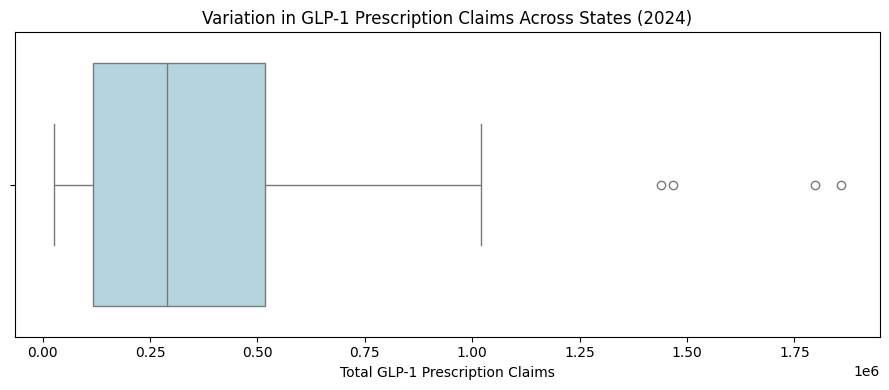

In [ ]:
plt.figure(figsize=(9, 4))

sns.boxplot(
    data=state_summary,
    x='total_claims',
    color='lightblue'
)

plt.title('Variation in GLP-1 Prescription Claims Across States (2024)')
plt.xlabel('Total GLP-1 Prescription Claims')
plt.tight_layout()
plt.show()

The exploratory visualizations show how total GLP-1 prescription claims vary across states in 2024. The histogram displays the distribution of prescription claims, while the boxplot helps identify unusually high or low values. These visualizations provide an initial overview of the dataset before examining relationships between prescription claims and economic characteristics.

## Part 2: Answer questions from the proposals (8 points)

Each plot should be followed by a paragraph of explanation and observation.

### Creator:

#### Question:

#### Question:

### Creator: Hannah Tran

#### Question: Do diabetes-focused GLP-1 medications, such as Ozempic and Trulicity, and weight-management medications, such as Wegovy and Zepbound, show different relationships with state median household income?

**Research Question:** Do diabetes-focused GLP-1 medications and weight-management GLP-1 medications show different relationships with state median household income?

**Year Analyzed:** 2024

For this question, we are examining whether state median household income is associated with the rates of GLP-1 prescribing for diabetes-focused and weight-management GLP-1 medications. We are categorizing diabetes-focused GLP-1 medications as Liraglutide, Ozempic, Rybelsus, Trulicity, Mounjaro, Victoza 2-Pak, Victoza 3-Pak, and Xultophy 100-3.6. We are categorizing weight-management GLP-1 medications as Wegovy and Zepbound. We will use a histogram

#### Answer:

In [ ]:
#data management
diabetes_brands = [
    'Liraglutide', 'Ozempic', 'Rybelsus', 'Trulicity', 'Mounjaro',
    'Victoza 2-Pak', 'Victoza 3-Pak', 'Xultophy 100-3.6'
]

merged_data_cat = merged_data.copy()
merged_data_cat['category'] = np.where(
    merged_data_cat['brand_name'].isin(diabetes_brands),
    'diabetes',
    'weight-management'
)

merged_data_cat['per_capita'] = merged_data_cat['total_claims']

display(merged_data_cat)

,geo_level,geo_code,State,brand_name,generic_name,total_prescribers,total_claims,total_30day_fills,total_drug_cost,total_beneficiaries,...,lis_bene_cost_share,non_lis_bene_cost_share,opioid_flag,long_acting_opioid_flag,antibiotic_flag,antipsychotic_flag,median_income,unemployment_rate,poverty_rate,category
0,State,01,Alabama,Liraglutide,Liraglutide,200,461,727.0,4.137233e+05,212.0,...,184.80,19293.93,N,N,N,N,66659,4.2,15.2,diabetes
1,State,01,Alabama,Mounjaro,Tirzepatide,3749,175463,202481.0,2.126128e+08,28948.0,...,264259.95,9023406.90,N,N,N,N,66659,4.2,15.2,diabetes
2,State,01,Alabama,Ozempic,Semaglutide,4238,226792,300214.0,2.734156e+08,43682.0,...,363577.40,13090612.42,N,N,N,N,66659,4.2,15.2,diabetes
3,State,01,Alabama,Rybelsus,Semaglutide,2318,29619,46573.7,4.324649e+07,7371.0,...,53010.86,1655845.17,N,N,N,N,66659,4.2,15.2,diabetes
4,State,01,Alabama,Trulicity,Dulaglutide,3254,72663,91879.1,8.799995e+07,13666.0,...,117025.75,3300031.82,N,N,N,N,66659,4.2,15.2,diabetes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
464,State,56,Wyoming,Trulicity,Dulaglutide,348,5143,6274.3,5.980668e+06,957.0,...,9238.78,485482.24,N,N,N,N,75532,3.4,10.1,diabetes
465,State,56,Wyoming,Victoza 2-Pak,Liraglutide,52,119,161.0,9.084368e+04,57.0,...,119.20,14401.64,N,N,N,N,75532,3.4,10.1,diabetes
466,State,56,Wyoming,Victoza 3-Pak,Liraglutide,85,366,523.5,3.605194e+05,107.0,...,542.80,48613.71,N,N,N,N,75532,3.4,10.1,diabetes
467,State,56,Wyoming,Wegovy,Semaglutide,39,181,187.3,2.464216e+05,45.0,...,407.80,29103.53,N,N,N,N,75532,3.4,10.1,weight-management


In [ ]:
#histogram
state_cat = (
    merged_data_cat
    .groupby(['State', 'category'], as_index=False)['rate']
    .sum()
)

### **Interpreter 1:** Aerin Borden


#### Question 8: How does the percentage of uninsured residents in a state relate to the number of Medicare Part D beneficiaries receiving GLP-1 medications?

**Research Question:** How does the percentage of uninsured residents in a state relate to the number of Medicare Part D beneficiaries receiving GLP-1 medications?

**Year Analyzed:** 2024

For this question, we examine the relationship between the percentage of residents without health insurance and the number of Medicare Part D beneficiaries receiving GLP-1 medications across the U.S.. To account for states with larger populations who naturally have more beneficiaries, we measure GLP-1 use as beneficiaries per 100,000 residents. We use a scatterplot with a regression line to examine the strength and direction of the association.

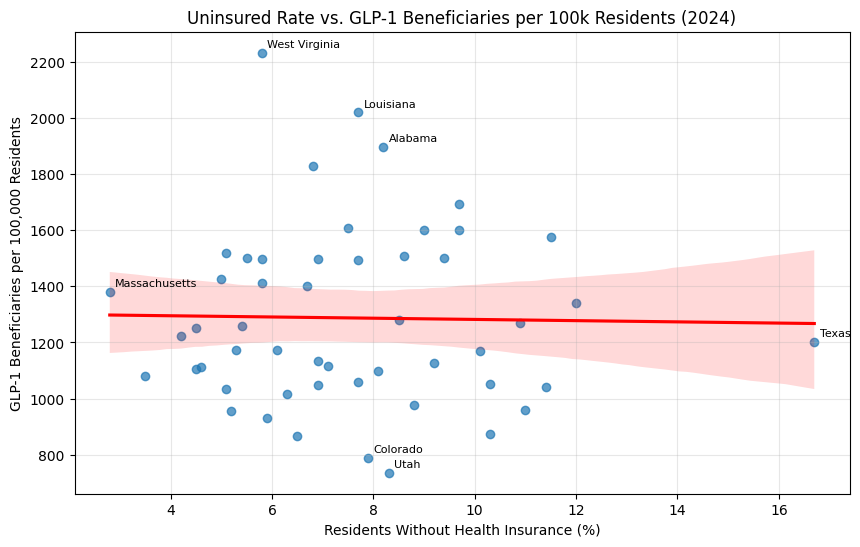

Correlation: -0.02


In [ ]:
# Graph 1 - Uninsured Rate vs. GLP-1 Beneficiaries per 100,000 Residents

aerin_merged = merged_data.copy()
aerin_census = census_long.copy()

def aerin_get_first(label, measure, new_name):
    out = (aerin_census[(aerin_census['Label (Grouping)'] == label) &
                        (aerin_census['Measure'] == measure)]
           .groupby('State', sort=False)['Value'].first()
           .reset_index().rename(columns={'Value': new_name}))
    out[new_name] = pd.to_numeric(out[new_name].astype(str)
                                  .str.replace(r'[,%]', '', regex=True), errors='coerce')
    return out

aerin_uninsured = aerin_get_first('No health insurance coverage', 'Percent', 'pct_uninsured')
aerin_population = aerin_get_first('Civilian noninstitutionalized population', 'Estimate', 'population')

# Total GLP-1 beneficiaries per state, then multiply to by population scale
q8 = (aerin_merged.groupby('State')
      .agg(glp_benes=('total_beneficiaries', lambda s: s.sum(min_count=1)))
      .reset_index()
      .merge(aerin_uninsured, on='State')
      .merge(aerin_population, on='State'))
q8['benes_per_100k'] = q8['glp_benes'] / q8['population'] * 100_000

plt.figure(figsize=(10, 6))

sns.regplot(
    data=q8,
    x='pct_uninsured',
    y='benes_per_100k',
    scatter_kws={'alpha': 0.7},
    line_kws={'color': 'red'}
)

# Label the highest, lowest, and most extreme states
for s in ['West Virginia', 'Louisiana', 'Alabama', 'Utah', 'Colorado', 'Texas', 'Massachusetts']:
    r = q8[q8['State'] == s].iloc[0]
    plt.annotate(s, (r['pct_uninsured'], r['benes_per_100k']), fontsize=8,
                 xytext=(4, 4), textcoords='offset points')

plt.title('Uninsured Rate vs. GLP-1 Beneficiaries per 100k Residents (2024)')
plt.xlabel('Residents Without Health Insurance (%)')
plt.ylabel('GLP-1 Beneficiaries per 100,000 Residents')
plt.grid(alpha=0.3)
plt.show()

print('Correlation:', round(q8['pct_uninsured'].corr(q8['benes_per_100k']), 2))

**Graph 1 - Uninsured Rate vs. GLP-1 Beneficiaries per 100k Residents (2024)**


The scatterplot examines the relationship between the percentage of residents without health insurance and the number of Medicare Part D GLP-1 beneficiaries per 100,000 residents across U.S. states in 2024. The trend line is almost completely flat, with the correlation (r = −0.02), indicating no linear relationship between the two variables. The data points are widely scattered, meaning states with similar uninsured rates can have very different levels of GLP-1 use. For example, West Virginia (just under 6% insured) has the highest rate (over 2,200 beneficiaries per 100,000 residents), while Colorado (just under 8%) and Utah (just over 8%) have the lowest (between 700 and 800). Texas is an outlier on the x-axis, with by far the highest uninsured rate (Over 16%), yet its GLP-1 rate (about 1,200) falls near the middle of the distribution.


#### Question 8 Answer:

Based on 2024 data, the percentage of uninsured residents in a state has no relationship with the number of Medicare Part D beneficiaries receiving GLP-1 medications (r = −0.02). This representation makes sense because nearly all adults 65 and older are covered by Medicare, so a state’s uninsured rate is mostly comprised of residents under 65, and those on Medicade are not included in this dataset. As a result, the uninsured rate does not directly measure insurance access for the patients in our data. The variation in GLP-1 use across states appears to follow geographic and health patterns instead, with the highest rates concentrated in Southern states. One limitation is that beneficiaries are summed across drugs, so a person who used more than one GLP-1 is counted more than once. In addition, three small beneficiary counts were suppressed by CMS (DC–Xultophy, Minnesota–Zepbound, New Hampshire–Zepbound), so those states are slightly undercounted.

**#### Question 8 Answer:**

### **Interpreter 2:** Evelyn Galvan

### **Question 1:** How does state median household income relate to the number of Medicare Part D beneficiaries receiving Ozempic and other GLP-1 medications across states and years?

**Research Question 5:** Which economic characteristics, median household income, poverty rate, or unemployment rate—are most strongly associated with GLP-1 prescription claims across states and years?

**Year Ananlyzed:** 2024

For this question, we examine the relationship between three socioeconomic factors and total Medicare Part D GLP-1 prescription claims across the 50 U.S. states and Washington, DC. Although the original research question considers multiple years, this analysis focuses on 2024 to establish an initial understanding of these relationships. We use three scatterplots and a correlation heatmap to compare the strength and direction of the associations.

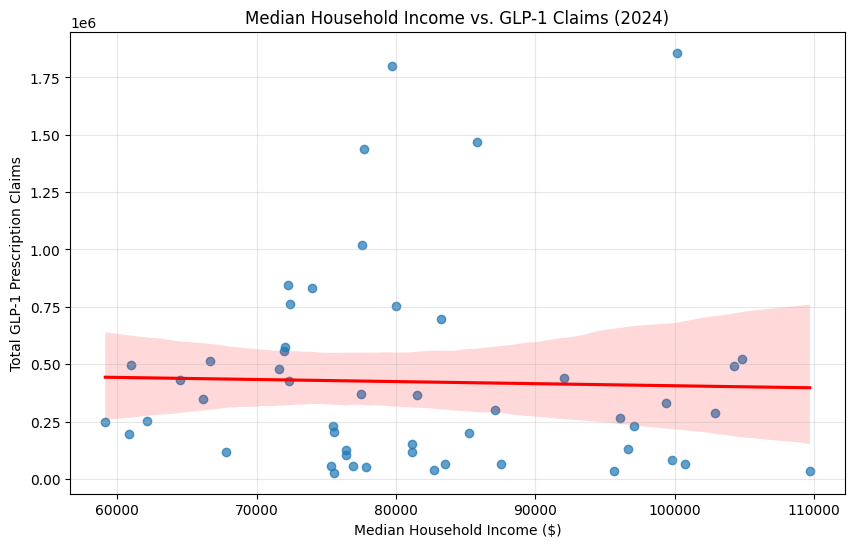

In [ ]:
# Graph 1 - Median Household Income vs. GLP-1 Claims

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.regplot(
    data=state_summary,
    x='median_income',
    y='total_claims',
    scatter_kws={'alpha': 0.7},
    line_kws={'color': 'red'}
)

plt.title('Median Household Income vs. GLP-1 Claims (2024)')
plt.xlabel('Median Household Income ($)')
plt.ylabel('Total GLP-1 Prescription Claims')
plt.grid(alpha=0.3)
plt.show()

**Graph 1 - Median Household Income vs. GLP-1 Prescription Claims (2024)**


The scatterplot examines the relationship between median household income and total GLP-1 prescription claims across U.S. states in 2024. Based on the graph, there appears to be a very weak negative relationship, as the trend line slopes slightly downward. The data points are widely scattered, suggesting that states with similar median household incomes can have very different numbers of GLP-1 prescription claims. There are also a few noticeable outliers with significantly higher prescription claims than most other states. Overall, the graph does not show a strong relationship between household income and total GLP-1 claims. However, differences in state population sizes and Medicare enrollment could influence the results, so total claims alone may not fully reflect differences in prescribing rates.

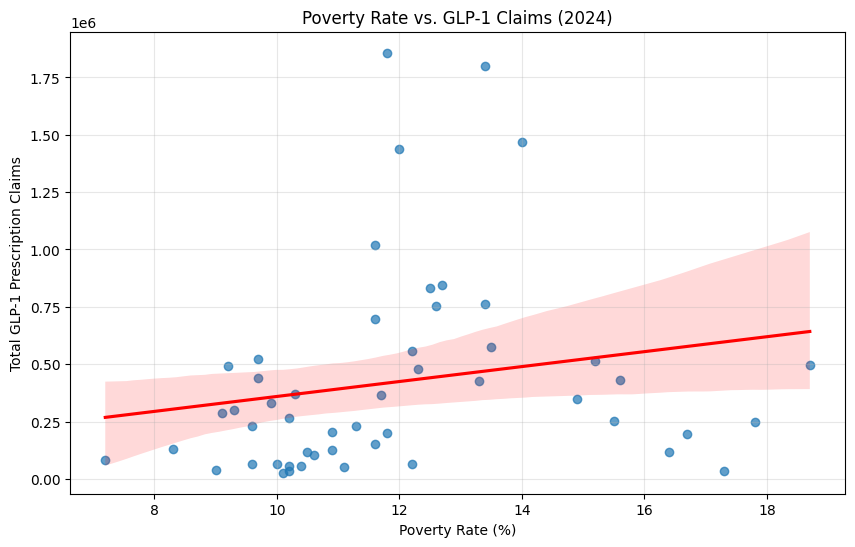

In [ ]:
# Graph 2 - Poverty Rate vs GLP-1 Claims

plt.figure(figsize=(10,6))

sns.regplot(
    data=state_summary,
    x='poverty_rate',
    y='total_claims',
    scatter_kws={'alpha': 0.7},
    line_kws={'color': 'red'}
)

plt.title('Poverty Rate vs. GLP-1 Claims (2024)')
plt.xlabel('Poverty Rate (%)')
plt.ylabel('Total GLP-1 Prescription Claims')
plt.grid(alpha=0.3)
plt.show()


**Graph 2 - Poverty Rate vs. GLP-1 Prescription Claims (2024)**

The scatterplot examines the relationship between poverty rates and total GLP-1 prescription claims across U.S. states in 2024. The graph shows a slight positive relationship, as the trend line slopes upward, suggesting that states with higher poverty rates tend to have somewhat higher prescription claim totals. However, the data points are widely scattered, indicating that the relationship is relatively weak. There are also several noticeable outliers, particularly among states with poverty rates between 11% and 14%, where prescription claims are significantly higher than in most other states. Overall, the results suggest that poverty rate alone does not strongly explain differences in GLP-1 prescription claims. State population size and Medicare enrollment may also influence these totals.

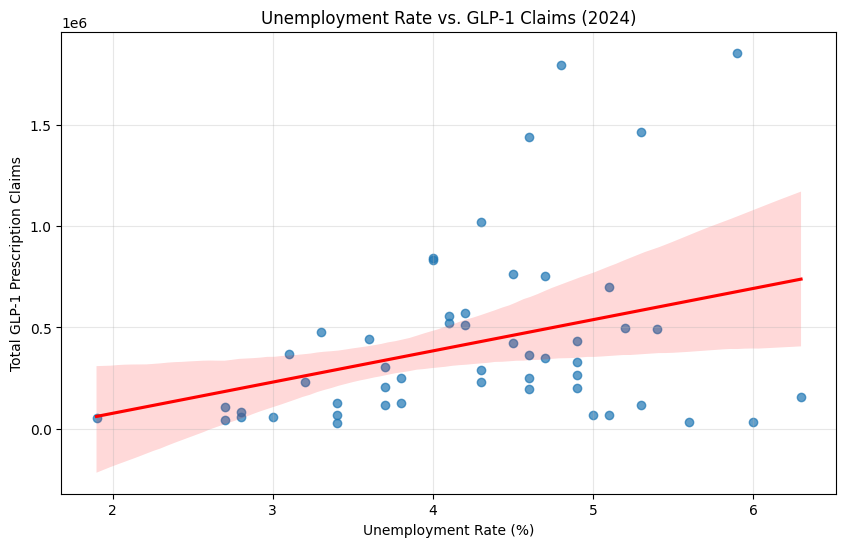

In [ ]:
# Graph 3 - Unemployment Rate vs. GLP-1 Claims

plt.figure(figsize=(10, 6))

sns.regplot(
    data=state_summary,
    x='unemployment_rate',
    y='total_claims',
    scatter_kws={'alpha': 0.7},
    line_kws={'color': 'red'}
)

plt.title('Unemployment Rate vs. GLP-1 Claims (2024)')
plt.xlabel('Unemployment Rate (%)')
plt.ylabel('Total GLP-1 Prescription Claims')
plt.grid(alpha=0.3)
plt.show()

**Graph 3 - Unemployment Rate vs. GLP-1 Prescription Claims (2024)**

The scatterplot examines the relationship between unemployment rates and total GLP-1 prescription claims across U.S. states in 2024. The graph shows a positive relationship, as the trend line slopes upward, suggesting that states with higher unemployment rates tend to have higher prescription claim totals. However, the data points are fairly spread out, indicating that the relationship is not very consistent across states. There are also several noticeable outliers, particularly among states with unemployment rates between 4.5% and 6%, where prescription claims are much higher than in most other states. Overall, the graph suggests that unemployment may be associated with differences in GLP-1 prescription claims, but unemployment alone does not explain the variation. Other factors, such as state population size and Medicare enrollment, may also influence the total number of claims.

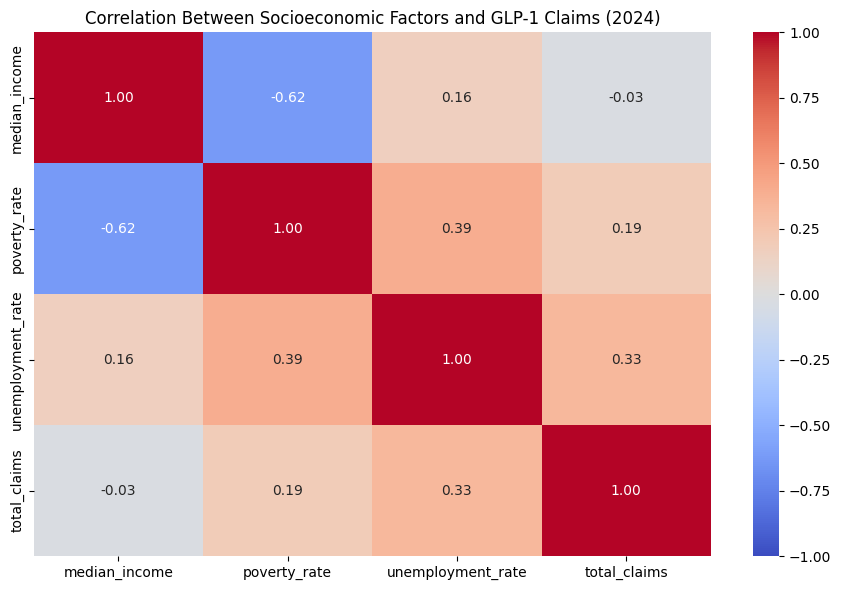

In [ ]:
# Graph 4 - Correlation Heatmap

correlations = state_summary[
    ['median_income', 'poverty_rate',
     'unemployment_rate', 'total_claims']
].corr()

# Create heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlations,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Between Socioeconomic Factors and GLP-1 Claims (2024)')
plt.tight_layout()
plt.show()


**Graph 4 - Correlation Between Socioeconomic Factors and GLP-1 Claims (2024)**

The correlation heatmap shows the relationships between median household income, poverty rates, unemployment rates, and total GLP-1 prescription claims across U.S. states in 2024. Median household income has almost no linear relationship with prescription claims, with a correlation of -0.03. Poverty rate has a weak positive correlation with claims (0.19), while unemployment rate has a somewhat stronger positive correlation (0.33). The heatmap also shows a moderately strong negative correlation between median household income and poverty rate (-0.62), suggesting that states with higher household incomes generally have lower poverty rates. Overall, unemployment has the strongest positive correlation with total GLP-1 claims among the three socioeconomic factors examined, although the relationship is still relatively modest. These findings suggest that socioeconomic factors may be associated with prescribing patterns, but differences in state population and Medicare enrollment could also influence the results.

### **Answer to Question 5**

Based on our analysis of 2024 data, unemployment rate appears to have the strongest association with total Medicare Part D GLP-1 prescription claims among the three socioeconomic factors examined. The correlation between unemployment rate and total claims is 0.33, compared with 0.19 for poverty rate and -0.03 for median household income. These results suggest that unemployment and poverty have positive but relatively weak associations with prescription claim totals, while median household income has almost no linear association.

However, these findings should be interpreted cautiously because states have different population sizes and numbers of Medicare Part D enrollees. States with larger Medicare populations may naturally have higher prescription claim totals regardless of their socioeconomic characteristics. Therefore, future analysis using claims per Medicare Part D enrollee would provide a more meaningful comparison of prescribing patterns across states. The current findings represent an initial 2024 analysis rather than a complete assessment of changes across multiple years.

### **Deliverer**: Estella Li

#### Question 4: Do states with similar median household incomes, poverty rates, and unemployment rates demonstrate similar GLP-1 prescription rates?

#### Answer:

#### Question 7: Are states with higher median household incomes associated with a greater number of GLP 1 prescription claims per reported Medicare beneficiary

#### Answer:

## Part 3: Follow-up Questions (4 points)

### New Questions Based Off Initial Investigation

- Q1: WRITE_QUESTION_HERE
- Q2: WRITE_QUESTION_HERE

## Summary (2 points)

Give a 2 paragraph summary.

Paragraph 1 should describe what you learned about your data from investigating the initial questions. Did you find anything unusual in your data? Did anything surprise you? Which of the initial questions were helpful in leading you to more questions?

Paragraph 2 should summarize what you learned from investigating the follow-up questions. Why are these follow-up questions interesting for investigation? Describe the tables/figures you used to explore answers to these follow-up questions? What did you learn from the tables/figures regarding the follow-up questions you proposed?

**Question 3: How does the relationship between median household income and GLP-1 prescription claims differ across individual GLP-1 medications in 2024?**

**Answer:** Our analysis of 2024 Medicare Part D prescription data examines whether the relationship between median household income and GLP-1 prescription claims varies depending on the medication. Across all GLP-1 medications combined, median household income has a very weak negative correlation with total prescription claims (r = −0.03), suggesting that household income alone does not strongly explain differences in GLP-1 prescribing across states. However, this overall correlation does not necessarily reflect the relationships for individual medications. Analyzing drugs separately, including Ozempic, Trulicity, Wegovy, and Zepbound, would allow us to determine whether certain medications are more strongly associated with state income levels than others.

The individual medication correlations have not yet been calculated, so we cannot conclude which drugs have stronger or weaker relationships with income. This analysis would help determine whether the weak overall association conceals differences in prescribing patterns across medications.

** Question 6: How do GLP-1 prescription volume, medication distribution, and average cost per claim differ between Southern and non-Southern states in 2024?**

**Answer:** Our analysis of 2024 Medicare Part D data examines regional differences in GLP-1 prescribing patterns by comparing Southern states with the rest of the United States. The preliminary exploratory analysis suggests that several Southern states have particularly high levels of GLP-1 use, indicating that geographic location may be associated with prescribing patterns. However, prescription volume varies considerably across individual states, suggesting that regional classification alone cannot explain these differences.

To investigate these patterns further, we compare average prescription claims per state, the percentage of claims attributed to each medication, and average drug cost per claim between the two regions. Comparing medication distributions allows us to identify whether particular GLP-1 drugs are more commonly prescribed in one region, while average cost per claim helps evaluate spending differences without relying solely on total expenditures. The regional comparisons have not yet been calculated, so we cannot definitively determine which region has higher average prescription volume, different medication preferences, or greater spending per claim. These comparisons will provide a more complete understanding of geographic differences in GLP-1 prescribing patterns.